# 03 · Dataset 3 — 가격 수준을 제거한 변화량 5개 피처 (KODEX 200, 069500)

**이 노트북이 하는 일**: 01 노트북의 클리닝 원천·급변 구간을 해시로 확인해 읽고, **가격의 절대 수준이 들어가지 않는** 변화량 피처 5개를 만든다.
가격 수준(`close` 등)은 연도에 따라 추세가 있어서, 모델이 "언제였는지"를 가격 수준으로 외울 수 있다. Dataset 3 은 그 경로를 막은 비교안이다.

| 피처 | 컬럼 | 계산 |
|---|---|---|
| 전일 대비 수익률 | `return_1d` | close_t / close_{t−1} − 1 |
| 시가 갭 | `gap_1d` | open_t / close_{t−1} − 1 |
| 당일 고저 범위 | `daily_range` | (high_t − low_t) / close_t |
| 고저 범위 변화 | `range_change_1d` | daily_range_t − daily_range_{t−1} |
| 거래량 변화율 | `volume_change_1d` | volume_t / volume_{t−1} − 1 (직전 거래량 0 → 결측 + 사유) |

`close`, `open`, `high`, `low` 는 계산에만 쓰고 학습 피처에는 넣지 않는다. 분할·표준화는 보류 (모델 설계와 함께 결정).

## 2. 실험 설정값

In [1]:
from pathlib import Path  # 경로 처리

ROOT = Path.cwd().parent  # 프로젝트 루트
TICKER = "069500"  # 종목코드
FEATURES = ["return_1d", "gap_1d", "daily_range", "range_change_1d", "volume_change_1d"]  # 피처 순서
PRICE_LEVEL_COLS = {"close", "open", "high", "low", "volume"}  # 학습 피처에 들어가면 안 되는 수준 컬럼
PROC = ROOT / "data/processed/dataset_3"  # 원값 폴더
TRAIN = ROOT / "data/training/dataset_3"  # 학습 배열 폴더
QUALITY = ROOT / "data/quality"  # 품질 폴더
FIG = ROOT / "reports/figures"  # 그림 폴더
for d in (PROC, TRAIN, QUALITY, FIG):  # 폴더 생성
    d.mkdir(parents=True, exist_ok=True)  # 있으면 그대로

## 3. 필수 라이브러리 및 버전 확인

In [2]:
import hashlib  # 해시
import json  # JSON
import platform  # 파이썬 버전
import numpy as np  # 수치
import pandas as pd  # 표
import matplotlib  # 버전
import matplotlib.pyplot as plt  # 그림

VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "matplotlib": matplotlib.__version__}  # 버전
plt.rcParams["font.family"] = ["NanumSquare", "Noto Sans CJK KR", "DejaVu Sans"]  # 한글 글꼴
plt.rcParams["axes.unicode_minus"] = False  # 음수 부호
print(VERSIONS)  # 출력


def save_pair(df: pd.DataFrame, path: Path) -> None:
    """parquet + 같은 이름 csv."""
    df.to_parquet(path, index=False)  # parquet
    df.to_csv(path.with_suffix(".csv"), index=False)  # csv


def content_hash(df: pd.DataFrame) -> str:
    """표 내용 SHA-256."""
    return hashlib.sha256(pd.util.hash_pandas_object(df, index=False).values.tobytes()).hexdigest()  # 내용 해시


def save_json(obj: dict, path: Path) -> None:
    """한글 JSON 저장."""
    path.write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str), encoding="utf-8")  # 저장

{'python': '3.12.3', 'numpy': '2.4.6', 'pandas': '3.0.3', 'matplotlib': '3.11.0'}


## 4. 입력 데이터 확인 (01 노트북 해시 대조)

In [3]:
done = json.loads((ROOT / "data/events/_NB1_DONE.json").read_text(encoding="utf-8"))  # 01 완료 기록
clean = pd.read_parquet(ROOT / done["clean"]["path"])  # 클리닝 원천
ev = pd.read_parquet(ROOT / done["events"]["path"])  # 급변 구간
nref = pd.read_parquet(ROOT / done["normal_windows"]["path"])  # 정상 구간
for key, tab in (("clean", clean), ("events", ev), ("normal_windows", nref)):  # 세 입력
    assert content_hash(tab) == done[key]["content_hash"], f"{key} 해시 불일치"  # 같은 입력인지
print("입력 해시 일치 | 행:", len(clean), "| 사건:", len(ev))  # 결과

입력 해시 일치 | 행: 2403 | 사건: 80


## 5. 공통 원천 로딩 · 6. 클리닝 결과 확인
수집하지 않는다. 클리닝 결과를 수정하지 않고, 이 데이터셋에 필요한 조건만 확인한다: 가격 양수, 거래량 0 인 날(나눗셈 분모) 목록.

In [4]:
assert (clean[["open", "high", "low", "close"]] > 0).all().all(), "비양수 가격"  # 비율 계산 가능 조건
zero_vol_dates = clean.loc[clean["volume"] == 0, "date"].dt.date.astype(str).tolist()  # 거래량 0 날 (다음 날 변화율 분모)
print("거래량 0 인 날:", zero_vol_dates)  # 출력

거래량 0 인 날: []


## 7. 피처 정제
직전 거래일 = 클리닝 표의 바로 앞 행. 거래량 변화율은 직전 거래량이 0 이면 무한대가 되므로 계산하지 않고 결측과 사유를 남긴다.

In [5]:
feat = clean[["ticker", "date"]].copy()  # 일별 피처 표
prev_close = clean["close"].shift(1)  # 직전 거래일 종가
feat["return_1d"] = clean["close"] / prev_close - 1  # 수익률
feat["gap_1d"] = clean["open"] / prev_close - 1  # 시가 갭
feat["daily_range"] = (clean["high"] - clean["low"]) / clean["close"]  # 고저 범위 비율
feat["range_change_1d"] = feat["daily_range"] - feat["daily_range"].shift(1)  # 고저 범위 변화 (비율의 차)
prev_vol = clean["volume"].shift(1)  # 직전 거래량
feat["volume_change_1d"] = np.where(prev_vol > 0, clean["volume"] / prev_vol.where(prev_vol > 0) - 1, np.nan)  # 분모 0·결측이면 결측
feat["missing_reason"] = np.select([prev_vol.isna(), prev_vol == 0], ["NO_PREVIOUS_DAY", "PREV_VOLUME_ZERO"], "")  # 결측 사유
save_pair(feat, PROC / "daily_features.parquet")  # 전체 일별 저장

## 8. 이벤트·날짜 정렬 (Dataset 1 과 같은 event_id·date·day_index)

In [6]:
main_ev = ev[ev["in_main_sample"]].sort_values("event_id").reset_index(drop=True)  # 표본 사건


def expand(windows: pd.DataFrame, id_col: str, extra: list) -> pd.DataFrame:
    """구간 → 하루 행."""
    parts = []  # 구간별
    for w in windows.itertuples(index=False):  # 구간마다
        part = feat[(feat["date"] >= w.start_date) & (feat["date"] <= w.end_date)].copy()  # 날짜 선택
        part.insert(0, id_col, getattr(w, id_col))  # ID
        for c in extra:  # 추가 식별
            part.insert(1, c, getattr(w, c))  # 컬럼
        part["day_index"] = np.arange(1, len(part) + 1)  # 순번
        parts.append(part)  # 추가
    return pd.concat(parts, ignore_index=True)  # 합침


rows = expand(main_ev, "event_id", [])[["event_id", "ticker", "date", "day_index"] + FEATURES + ["missing_reason"]]  # 사건 행
save_pair(rows, PROC / "event_rows.parquet")  # 저장
nrows = expand(nref[nref["matched"]], "ref_id", ["matched_event_id"])[["ref_id", "matched_event_id", "ticker", "date", "day_index"] + FEATURES + ["missing_reason"]]  # 정상 행
save_pair(nrows, PROC / "normal_reference.parquet")  # 저장
d1 = pd.read_parquet(ROOT / "data/processed/dataset_1/event_rows.parquet")  # Dataset 1
d2p = ROOT / "data/processed/dataset_2/event_rows.parquet"  # Dataset 2 경로
key = ["event_id", "date", "day_index"]  # 정렬 키
same_d1 = d1[key].equals(rows[key])  # Dataset 1 과 동일
same_d2 = pd.read_parquet(d2p)[key].equals(rows[key]) if d2p.exists() else None  # Dataset 2 와 동일 (있을 때)
assert same_d1, "Dataset 1 과 정렬 불일치"  # 계약 위반이면 중단
print("사건 행:", rows.shape, "| D1 정렬:", same_d1, "| D2 정렬:", same_d2)  # 결과

사건 행: (891, 10) | D1 정렬: True | D2 정렬: True


## 9. 결측·분포·이상값 검사

결측: {'return_1d': 0, 'gap_1d': 0, 'daily_range': 0, 'range_change_1d': 0, 'volume_change_1d': 0} 
왜도: {'return_1d': 0.76, 'gap_1d': 0.34, 'daily_range': 3.6, 'range_change_1d': 0.32, 'volume_change_1d': 1.62}


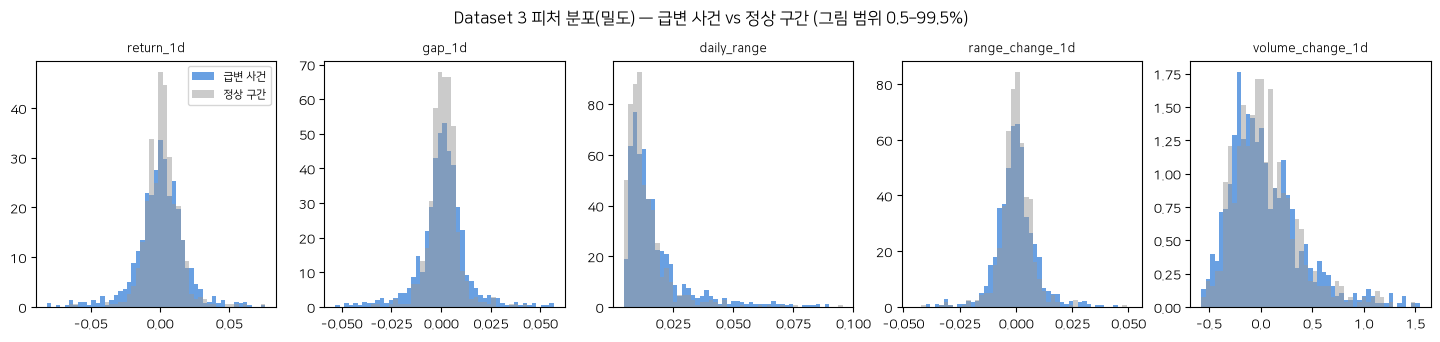

In [7]:
miss = rows[FEATURES].isna().sum()  # 피처별 결측
skew = rows[FEATURES].skew()  # 왜도
print("결측:", miss.to_dict(), "\n왜도:", skew.round(2).to_dict())  # 출력
fig, axes = plt.subplots(1, 5, figsize=(18, 3.2))  # 분포 비교
for ax, c in zip(axes, FEATURES):  # 피처마다
    lo, hi = np.nanquantile(pd.concat([rows[c], nrows[c]]), [0.005, 0.995])  # 꼬리 0.5% 밖은 그림 범위에서만 제외
    bins = np.linspace(lo, hi, 50)  # 같은 구간
    ax.hist(rows[c].dropna(), bins=bins, alpha=0.7, color="#2a78d6", density=True, label="급변 사건")  # 사건
    ax.hist(nrows[c].dropna(), bins=bins, alpha=0.5, color="#999999", density=True, label="정상 구간")  # 정상
    ax.set_title(c, fontsize=9)  # 제목
axes[0].legend(fontsize=8)  # 범례
fig.suptitle("Dataset 3 피처 분포(밀도) — 급변 사건 vs 정상 구간 (그림 범위 0.5–99.5%)", y=1.04)  # 제목
fig.savefig(FIG / "03_feature_distributions.png", dpi=130, bbox_inches="tight")  # 저장
plt.show()  # 표시

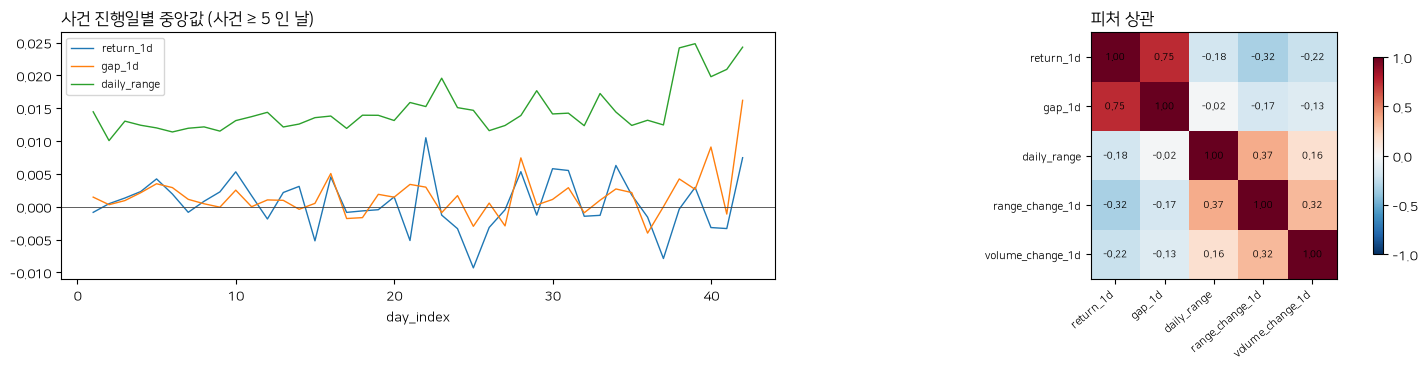

In [8]:
prof = rows.groupby("day_index")[FEATURES].median()  # 사건 진행일별 중앙값
cnt = rows.groupby("day_index").size()  # 진행일별 사건 수
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))  # 두 그림
for c in ("return_1d", "gap_1d", "daily_range"):  # 세 피처
    ax[0].plot(prof.index[cnt >= 5], prof.loc[cnt >= 5, c], lw=1, label=c)  # 사건 5개 이상인 진행일만
ax[0].axhline(0, color="#444444", lw=0.6); ax[0].legend(fontsize=8); ax[0].set_xlabel("day_index"); ax[0].set_title("사건 진행일별 중앙값 (사건 ≥ 5 인 날)", loc="left")  # 꾸미기
cm = rows[FEATURES].corr().to_numpy()  # 상관
im = ax[1].imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)  # 히트맵
ax[1].set_xticks(range(5), FEATURES, rotation=40, ha="right", fontsize=8); ax[1].set_yticks(range(5), FEATURES, fontsize=8)  # 눈금
for i in range(5):  # 값 표기
    for j in range(5):  # 열
        ax[1].text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7)  # 값
ax[1].set_title("피처 상관", loc="left"); fig.colorbar(im, ax=ax[1], shrink=0.8)  # 꾸미기
fig.tight_layout(); fig.savefig(FIG / "03_event_profile_corr.png", dpi=130, bbox_inches="tight")  # 저장
plt.show()  # 표시

## 10. 학습·검증 분할과 표준화 — 보류 (모델 설계와 함께 결정)

In [9]:
tr_ev = main_ev[["event_id", "start_date", "end_date", "duration_days", "analysis_year"]].copy()  # 이벤트 메타
tr_ev["crosses_year_boundary"] = tr_ev["start_date"].dt.year != tr_ev["end_date"].dt.year  # 연도 걸침
ok = rows.assign(ok=rows[FEATURES].notna().all(axis=1)).groupby("event_id")["ok"].sum()  # 사건별 유효 날 수
tr_ev["n_valid_rows"] = tr_ev["event_id"].map(ok).astype(int)  # 추가
tr_ev["fully_valid"] = tr_ev["n_valid_rows"] == tr_ev["duration_days"]  # 결측 없는 사건
save_pair(tr_ev, TRAIN / "events.parquet")  # 저장
save_json({"split_status": "DEFERRED_UNTIL_MODEL_DESIGN", "assignment": None, "see_also": "data/training/dataset_1/split_manifest.json (공통 의견)", "events_by_year": tr_ev.groupby("analysis_year").size().to_dict(), "dataset_3_notes": ["가격 수준이 없으므로 연도별 가격 추세로 분할 간 분포가 달라지는 문제는 Dataset 1 보다 작다.", "volume_change_1d 는 오른쪽 꼬리가 길다 — 학습 분할 기준 log1p(1+x) 변환 후보."]}, TRAIN / "split_manifest.json")  # 분할 보류
save_json({"status": "NOT_FITTED", "rule": "학습 분할의 obs_mask & ~missing_mask 위치에서만 피처별 평균·표준편차 적합", "transform_candidates": {"volume_change_1d": {"transform": "log(1 + x)", "reason": f"왜도 {skew['volume_change_1d']:.2f}, x > −1 이므로 정의됨"}}, "descriptive_only": rows[FEATURES].describe().round(6).to_dict()}, TRAIN / "scaler.json")  # 표준화 규칙

## 11. 가변 길이 학습 데이터 출력

In [10]:
def to_tensor(tab: pd.DataFrame, id_col: str, feats: list):
    """하루 행 → (X, obs_mask, missing_mask, lengths, ids)."""
    ids = np.array(sorted(tab[id_col].unique()))  # ID 정렬
    groups = {k: g.sort_values("day_index") for k, g in tab.groupby(id_col)}  # 구간별
    lengths = np.array([len(groups[k]) for k in ids], dtype=np.int32)  # 길이
    X = np.zeros((len(ids), int(lengths.max()), len(feats)), dtype=np.float32)  # 값 (0 패딩)
    obs = np.zeros(X.shape[:2], dtype=bool)  # 실제 날짜
    mis = np.zeros(X.shape, dtype=bool)  # 결측
    for i, k in enumerate(ids):  # 구간마다
        v = groups[k][feats].to_numpy(dtype="float64")  # 값
        obs[i, :len(v)] = True  # 실제 날짜
        mis[i, :len(v)] = ~np.isfinite(v)  # 결측
        X[i, :len(v)] = np.where(np.isfinite(v), v, 0.0)  # 결측 → 0
    return X, obs, mis, lengths, ids  # 반환


X, obs, mis, lengths, ids = to_tensor(rows, "event_id", FEATURES)  # 사건 배열
np.savez_compressed(TRAIN / "features.npz", X=X, obs_mask=obs, missing_mask=mis, lengths=lengths, event_ids=ids, feature_names=np.array(FEATURES))  # 저장
Xn, obsn, misn, lenn, idsn = to_tensor(nrows, "ref_id", FEATURES)  # 정상 구간
np.savez_compressed(TRAIN / "normal_reference_features.npz", X=Xn, obs_mask=obsn, missing_mask=misn, lengths=lenn, ref_ids=idsn, feature_names=np.array(FEATURES))  # 저장
FORMULA = {"return_1d": "close_t/close_{t-1}-1", "gap_1d": "open_t/close_{t-1}-1", "daily_range": "(high_t-low_t)/close_t", "range_change_1d": "daily_range_t-daily_range_{t-1}", "volume_change_1d": "volume_t/volume_{t-1}-1 (prev 0 -> NaN)"}  # 식
save_json({"features": [{"index": i, "name": f, "dtype": "float32", "unit": "소수", "formula": FORMULA[f], "info_time": "close_t (직전일 값 참조)"} for i, f in enumerate(FEATURES)], "excluded_price_levels": sorted(PRICE_LEVEL_COLS), "axis_order": "X[event, day, feature]"}, TRAIN / "feature_columns.json")  # 피처 정의
print("X:", X.shape, "| 결측 칸:", int(mis.sum()), "| 정상 X:", Xn.shape)  # 정보

X: (64, 63, 5) | 결측 칸: 0 | 정상 X: (57, 61, 5)


## 12. 품질 검증 및 재현성 검사
- 학습 피처에 가격 수준이 없는지
- 수익률·변화량을 원천 가격에서 **행 위치 기반으로 독립 재계산**해 일치하는지
- Dataset 1 과 공통 피처(`return_1d`, `gap_1d`, `daily_range`) 값이 같은지

In [11]:
chk = {}  # 검사
chk["no_price_level_features"] = not (set(FEATURES) & PRICE_LEVEL_COLS)  # 수준 컬럼 없음
pos = pd.Series(np.arange(len(clean)), index=clean["date"])[rows["date"]].to_numpy()  # 사건 날짜의 원천 행 위치
c, o, h, l, v = (clean[k].to_numpy() for k in ("close", "open", "high", "low", "volume"))  # 원천 배열
rng_ = (h - l) / c  # 고저 범위
re = np.c_[c[pos] / c[pos - 1] - 1, o[pos] / c[pos - 1] - 1, rng_[pos], rng_[pos] - rng_[pos - 1], np.where(v[pos - 1] > 0, v[pos] / np.where(v[pos - 1] > 0, v[pos - 1], 1) - 1, np.nan)]  # 독립 재계산
diff = float(np.nanmax(np.abs(re - rows[FEATURES].to_numpy(dtype="float64"))))  # 최대 차이
assert diff < 1e-12, "원천 재계산 불일치"  # 위반이면 중단
chk["recompute_from_prices_max_diff"] = diff  # 기록
chk["same_as_dataset_1_common_features"] = bool(np.allclose(d1[["return_1d", "gap_1d", "daily_range"]].to_numpy(dtype="float64"), rows[["return_1d", "gap_1d", "daily_range"]].to_numpy(dtype="float64")))  # D1 과 동일
chk["event_alignment_d1"] = bool(same_d1)  # 정렬
chk["event_alignment_d2"] = same_d2 if same_d2 is not None else "D2_NOT_FOUND"  # 정렬
chk["no_inf"] = bool(np.isfinite(rows[FEATURES].to_numpy(dtype="float64")[rows[FEATURES].notna().to_numpy()]).all())  # 무한대 없음
chk["feature_count"] = {"expected": 5, "actual": int(X.shape[2]), "pass": X.shape[2] == 5}  # 피처 수
chk["missing_with_reason"] = bool((rows.loc[rows[FEATURES].isna().any(axis=1), "missing_reason"] != "").all())  # 결측마다 사유
chk["uses_only_t_and_t_minus_1"] = True  # 위 재계산이 pos 와 pos−1 만 사용 → 확인됨
chk["scaler_not_fitted"] = True  # 분할 보류
fails = [k for k, val in chk.items() if val is False or (isinstance(val, dict) and val.get("pass") is False)]  # 실패
status = "TRAIN_READY" if not fails else "PARTIAL"  # 판정
save_json({"dataset": "dataset_3", "checks": chk, "fails": fails, "missing": miss.to_dict(), "status": status, "split_status": "DEFERRED_UNTIL_MODEL_DESIGN"}, QUALITY / "dataset_3_validation.json")  # 검증 보고
out_hash = {p: content_hash(pd.read_parquet(ROOT / p)) for p in ["data/processed/dataset_3/daily_features.parquet", "data/processed/dataset_3/event_rows.parquet", "data/processed/dataset_3/normal_reference.parquet", "data/training/dataset_3/events.parquet"]}  # 출력 해시
out_hash["features.npz:X"] = hashlib.sha256(X.tobytes()).hexdigest()  # 배열 해시
save_json({"dataset": "dataset_3", "status": status, "split_status": "DEFERRED_UNTIL_MODEL_DESIGN", "input_hashes": done, "versions": VERSIONS, "n_events": int(X.shape[0]), "tensor_shape": list(X.shape), "features": FEATURES, "outputs_content_hash": out_hash, "validation_fails": fails}, TRAIN / "dataset_manifest.json")  # manifest

# 데이터셋 간 검증: 세 데이터셋 이벤트·날짜 동일, 공통 유효 이벤트 집합
cross = {}  # 결과
ev_sets = {}  # 데이터셋별 결측 없는 사건
for k in (1, 2, 3):  # 데이터셋마다
    p = ROOT / f"data/training/dataset_{k}/events.parquet"  # 이벤트 메타
    if p.exists():  # 있을 때
        t = pd.read_parquet(p)  # 읽기
        ev_sets[k] = set(t.loc[t["fully_valid"], "event_id"])  # 결측 없는 사건
        cross[f"dataset_{k}_events"] = int(len(t))  # 전체 사건 수
cross["all_event_ids_identical"] = bool(all(pd.read_parquet(ROOT / f"data/training/dataset_{k}/events.parquet")["event_id"].tolist() == tr_ev["event_id"].tolist() for k in ev_sets))  # 전체 목록 동일
common = sorted(set.intersection(*ev_sets.values())) if ev_sets else []  # 공통 유효 사건
cross["common_fully_valid_events"] = len(common)  # 개수
cross["note"] = "채널 수가 다르므로(5·7·5) 전체 복원오차를 단순 비교해 우열을 정하지 않는다. 직접 비교는 공통 유효 사건 집합에서 채널당 지표로."  # 주의
pd.DataFrame({"event_id": common}).pipe(lambda d: save_pair(d, QUALITY / "common_valid_events.parquet"))  # 공통 집합 저장
save_json(cross, QUALITY / "cross_dataset_validation.json")  # 저장
print(json.dumps({"status": status, "fails": fails, **cross}, ensure_ascii=False))  # 결과
chk  # 검사 표

{"status": "TRAIN_READY", "fails": [], "dataset_1_events": 64, "dataset_2_events": 64, "dataset_3_events": 64, "all_event_ids_identical": true, "common_fully_valid_events": 64, "note": "채널 수가 다르므로(5·7·5) 전체 복원오차를 단순 비교해 우열을 정하지 않는다. 직접 비교는 공통 유효 사건 집합에서 채널당 지표로."}


{'no_price_level_features': True,
 'recompute_from_prices_max_diff': 0.0,
 'same_as_dataset_1_common_features': True,
 'event_alignment_d1': True,
 'event_alignment_d2': True,
 'no_inf': True,
 'feature_count': {'expected': 5, 'actual': 5, 'pass': True},
 'missing_with_reason': True,
 'uses_only_t_and_t_minus_1': True,
 'scaler_not_fitted': True}

## 13. 결과 요약 및 데이터 계약
- 원값: `data/processed/dataset_3/event_rows.parquet` (결측 사유 `missing_reason` 포함), 정상 구간 `normal_reference.parquet`.
- 학습: `data/training/dataset_3/` — 가격 수준 없음, Dataset 1·2 와 같은 사건·날짜 순서.
- 데이터셋 간 검증: `data/quality/cross_dataset_validation.json`, 공통 유효 사건 `common_valid_events.parquet`.
- 분할·표준화는 보류 — `scaler.json` 의 규칙과 변환 후보를 학습 단계에서 적용한다.